# Assignment-02: AE, VAE, DCGAN and Stable Diffusion
**Before running:** Runtime > Change runtime type > **T4 GPU**. Run cells top to bottom and take screenshots of the plots (input, AE/VAE reconstructions, DCGAN grid, Stable Diffusion images).

### Name : Nikheel c Khadakabhavi
### PRN : 202401110020

## Activity A - Autoencoder vs VAE (CO3)

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, torchvision, torchvision.transforms as T
import matplotlib.pyplot as plt
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
tf = T.ToTensor()
train = torchvision.datasets.MNIST('.', train=True, download=True, transform=tf)
test = torchvision.datasets.MNIST('.', train=False, download=True, transform=tf)
dl = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.95MB/s]


In [2]:
class AE(nn.Module):
    def __init__(s, d=16):
        super().__init__()
        s.e = nn.Sequential(nn.Flatten(), nn.Linear(784,256), nn.ReLU(), nn.Linear(256,d))
        s.d = nn.Sequential(nn.Linear(d,256), nn.ReLU(), nn.Linear(256,784), nn.Sigmoid())
    def forward(s, x): return s.d(s.e(x)).view(-1,1,28,28)

class VAE(nn.Module):
    def __init__(s, d=16):
        super().__init__()
        s.e = nn.Sequential(nn.Flatten(), nn.Linear(784,256), nn.ReLU())
        s.mu, s.lv = nn.Linear(256,d), nn.Linear(256,d)
        s.d = nn.Sequential(nn.Linear(d,256), nn.ReLU(), nn.Linear(256,784), nn.Sigmoid())
    def forward(s, x):
        h = s.e(x); mu, lv = s.mu(h), s.lv(h)
        z = mu + torch.randn_like(mu) * torch.exp(0.5*lv)   # reparameterisation trick
        return s.d(z).view(-1,1,28,28), mu, lv

def fit(m, vae, epochs=10):
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epochs):
        for x,_ in dl:
            x = x.to(dev)
            if vae:
                r, mu, lv = m(x)
                loss = F.binary_cross_entropy(r, x, reduction='sum') - 0.5*torch.sum(1 + lv - mu**2 - lv.exp())
            else:
                loss = F.binary_cross_entropy(m(x), x, reduction='sum')
            opt.zero_grad(); (loss/len(x)).backward(); opt.step()
        print(type(m).__name__, 'epoch', ep+1, 'loss/img', round(loss.item()/len(x),2))

ae, vae = AE().to(dev), VAE().to(dev)
fit(ae, False); fit(vae, True)

AE epoch 1 loss/img 96.02
AE epoch 2 loss/img 85.95
AE epoch 3 loss/img 88.67
AE epoch 4 loss/img 77.59
AE epoch 5 loss/img 78.48
AE epoch 6 loss/img 77.62
AE epoch 7 loss/img 79.12
AE epoch 8 loss/img 79.81
AE epoch 9 loss/img 74.43
AE epoch 10 loss/img 74.68
VAE epoch 1 loss/img 135.88
VAE epoch 2 loss/img 121.24
VAE epoch 3 loss/img 109.49
VAE epoch 4 loss/img 111.97
VAE epoch 5 loss/img 110.9
VAE epoch 6 loss/img 108.95
VAE epoch 7 loss/img 108.89
VAE epoch 8 loss/img 108.55
VAE epoch 9 loss/img 109.71
VAE epoch 10 loss/img 107.79


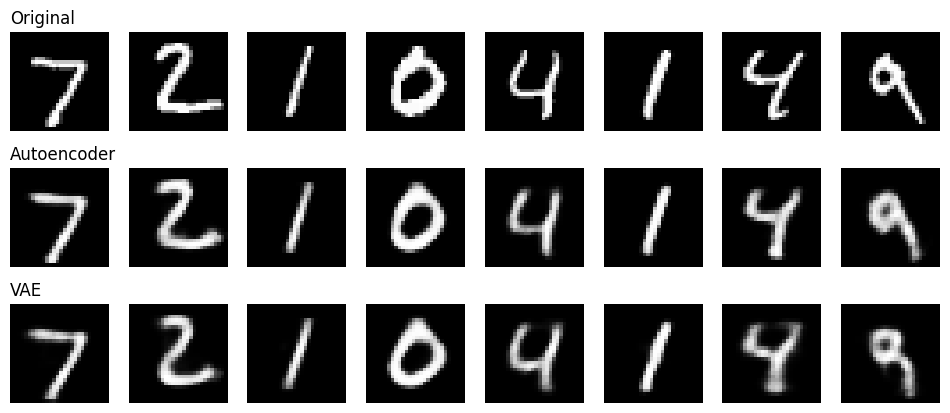

MSE  AE : 0.01149763073772192 
MSE  VAE: 0.01557916309684515


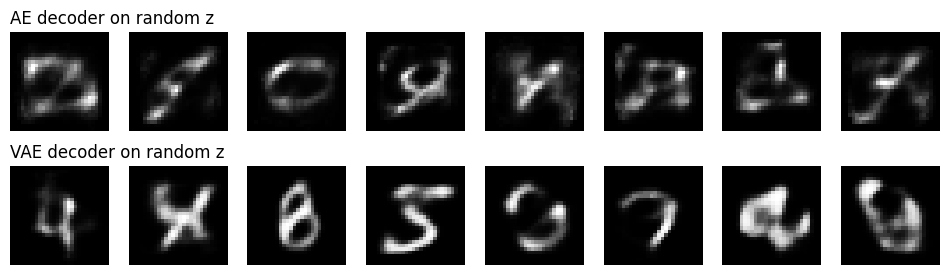

In [3]:
# Input images: first 8 MNIST test digits.
# OPTIONAL - use your own image instead (uncomment):
# from google.colab import files; from PIL import Image
# up = files.upload(); im = Image.open(list(up)[0]).convert('L').resize((28,28))
# x = tf(im).unsqueeze(0).to(dev)
x = torch.stack([test[i][0] for i in range(8)]).to(dev)
ae.eval(); vae.eval()
with torch.no_grad(): ra = ae(x); rv = vae(x)[0]
fig, ax = plt.subplots(3, len(x), figsize=(len(x)*1.5, 5), squeeze=False)
for r,(imgs,name) in enumerate(zip([x,ra,rv], ['Original','Autoencoder','VAE'])):
    for c in range(len(x)):
        ax[r][c].imshow(imgs[c,0].cpu(), cmap='gray'); ax[r][c].axis('off')
    ax[r][0].set_title(name, loc='left')
plt.show()
xt = torch.stack([test[i][0] for i in range(1000)]).to(dev)
with torch.no_grad(): print('MSE  AE :', F.mse_loss(ae(xt), xt).item(), '\nMSE  VAE:', F.mse_loss(vae(xt)[0], xt).item())
# Bonus: decode random latent vectors (AE cannot generate, VAE can)
with torch.no_grad(): z = torch.randn(8,16,device=dev); ga, gv = ae.d(z).view(-1,1,28,28), vae.d(z).view(-1,1,28,28)
fig, ax = plt.subplots(2, 8, figsize=(12,3.2))
for c in range(8):
    ax[0][c].imshow(ga[c,0].cpu(), cmap='gray'); ax[1][c].imshow(gv[c,0].cpu(), cmap='gray'); ax[0][c].axis('off'); ax[1][c].axis('off')
ax[0][0].set_title('AE decoder on random z', loc='left'); ax[1][0].set_title('VAE decoder on random z', loc='left'); plt.show()

## Activity B1 - DCGAN (CO4)

epoch 1 D loss 0.582 G loss 1.194
epoch 2 D loss 0.72 G loss 2.623
epoch 3 D loss 0.528 G loss 1.358
epoch 4 D loss 0.68 G loss 2.026
epoch 5 D loss 0.709 G loss 1.412
epoch 6 D loss 0.562 G loss 2.021
epoch 7 D loss 0.556 G loss 1.602
epoch 8 D loss 0.597 G loss 1.36
epoch 9 D loss 0.5 G loss 2.671
epoch 10 D loss 0.639 G loss 1.579


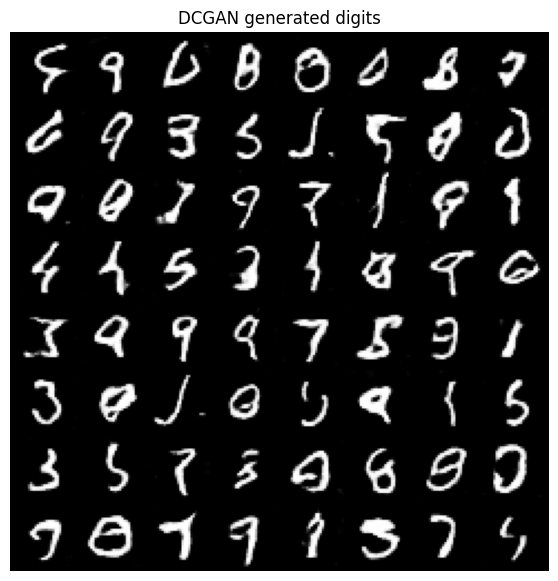

In [4]:
nz = 100
class G(nn.Module):
    def __init__(s):
        super().__init__()
        s.n = nn.Sequential(nn.ConvTranspose2d(nz,128,7,1,0,bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
                            nn.ConvTranspose2d(128,64,4,2,1,bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
                            nn.ConvTranspose2d(64,1,4,2,1,bias=False), nn.Tanh())
    def forward(s, z): return s.n(z)
class D(nn.Module):
    def __init__(s):
        super().__init__()
        s.n = nn.Sequential(nn.Conv2d(1,64,4,2,1,bias=False), nn.LeakyReLU(0.2,True),
                            nn.Conv2d(64,128,4,2,1,bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2,True),
                            nn.Conv2d(128,1,7,1,0,bias=False))
    def forward(s, x): return s.n(x).view(-1)
tf2 = T.Compose([T.ToTensor(), T.Normalize((0.5,),(0.5,))])
dl2 = torch.utils.data.DataLoader(torchvision.datasets.MNIST('.', train=True, transform=tf2), batch_size=128, shuffle=True)
g, d = G().to(dev), D().to(dev)
og = torch.optim.Adam(g.parameters(), 2e-4, betas=(0.5,0.999)); od = torch.optim.Adam(d.parameters(), 2e-4, betas=(0.5,0.999))
bce = nn.BCEWithLogitsLoss()
for ep in range(10):
    for x,_ in dl2:
        x = x.to(dev); b = len(x)
        fake = g(torch.randn(b,nz,1,1,device=dev))
        ld = bce(d(x), torch.ones(b,device=dev)) + bce(d(fake.detach()), torch.zeros(b,device=dev))
        od.zero_grad(); ld.backward(); od.step()
        lg = bce(d(fake), torch.ones(b,device=dev))
        og.zero_grad(); lg.backward(); og.step()
    print('epoch', ep+1, 'D loss', round(ld.item(),3), 'G loss', round(lg.item(),3))
g.eval()
with torch.no_grad(): s = g(torch.randn(64,nz,1,1,device=dev)).cpu()*0.5+0.5
plt.figure(figsize=(7,7)); plt.imshow(torchvision.utils.make_grid(s, nrow=8).permute(1,2,0)); plt.axis('off'); plt.title('DCGAN generated digits'); plt.show()

## Activity B2 - Pretrained Stable Diffusion (CO4)
First run downloads ~4 GB (a few minutes). Change the prompts if you like and note the ones you use in the report.

In [5]:
!pip -q install diffusers transformers accelerate

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

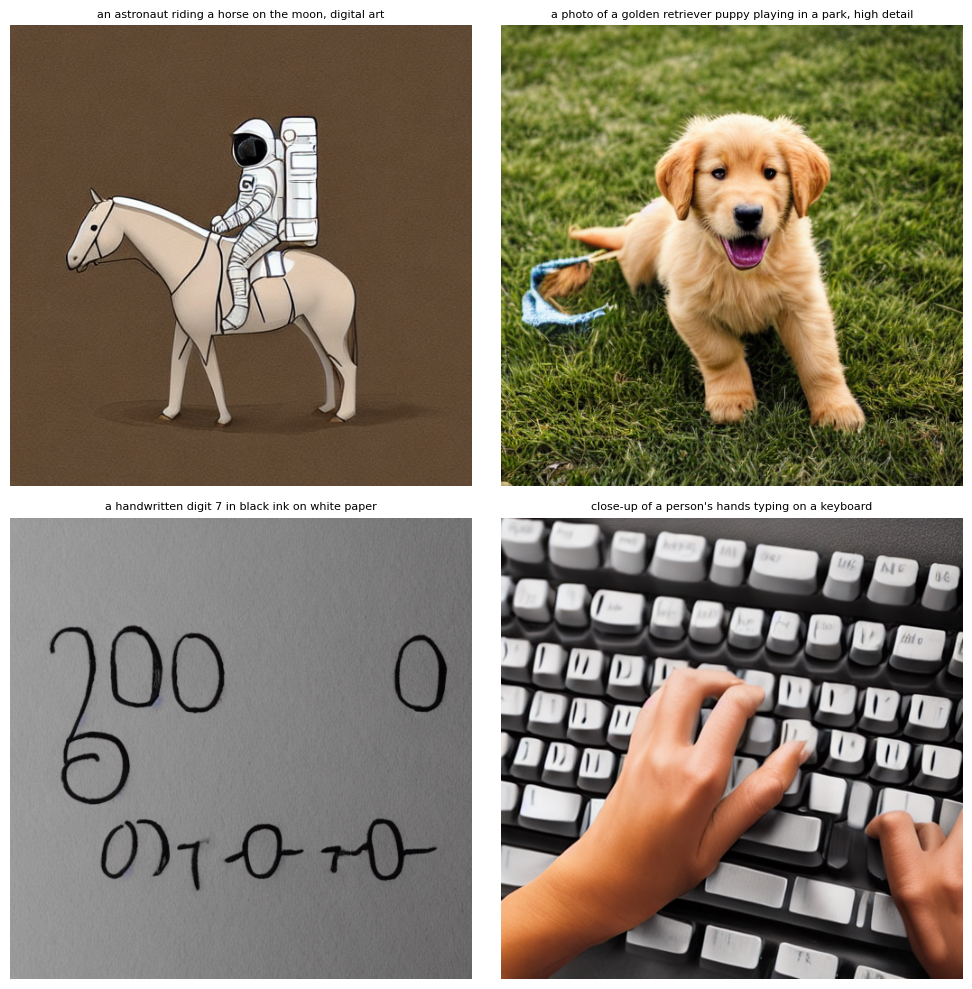

In [6]:
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained('stable-diffusion-v1-5/stable-diffusion-v1-5', torch_dtype=torch.float16).to('cuda')
prompts = ['an astronaut riding a horse on the moon, digital art',
           'a photo of a golden retriever puppy playing in a park, high detail',
           'a handwritten digit 7 in black ink on white paper',
           'close-up of a person\'s hands typing on a keyboard']   # last one tests known weak spots (hands)
imgs = [pipe(p, num_inference_steps=30, guidance_scale=7.5, generator=torch.Generator('cuda').manual_seed(42)).images[0] for p in prompts]
fig, ax = plt.subplots(2, 2, figsize=(10,10))
for a,im,p in zip(ax.flat, imgs, prompts): a.imshow(im); a.axis('off'); a.set_title(p, fontsize=8)
plt.tight_layout(); plt.show()